# SakAI Final Demo

## External testing as a baseline for Paoay, Atok

**Can a crop classifier trained in one region recognize carrot, cabbage, and potato in another? And how much can a small set of labels from the target region help?**

We trained two models on labeled European fields and tested them on the **same 111 separate JECAM fields**. This external-to-external test is the transfer baseline for the upcoming Paoay application. The frozen models scored **0.307 fixed** and **0.292 green-up aligned** in field-level macro-F1. Both exceeded the potato-only baseline of **0.210**.

In [Experiments](#Experiments), a separate comparison adds **23 labeled fields from Madagascar and Senegal**. We score every version on the same **88 held-out fields**. That comparison helps us plan how to collect and test local labels when we apply SakAI in Paoay.

[Jump to external testing](#External-testing) · [Project design](../docs/project_design.md)

## Data collection

### 1. Start with fields where we know the crop

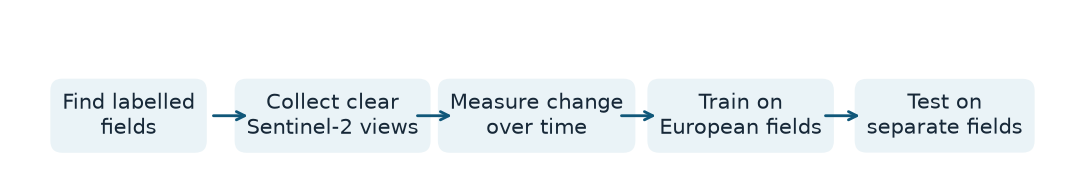

The workflow pairs crop records with Sentinel-2 imagery from the same fields. The JECAM labels stay outside development training and validation for the frozen transfer test.

[Full walkthrough](SakAI_crop_classification_walkthrough.ipynb)

### 2. Meet the datasets

**All development fields come from Europe**, mainly Spain, France, and the Netherlands. The map shows the matched fields used in the comparisons in this demo. Paoay in Atok, Benguet is the planned application area.

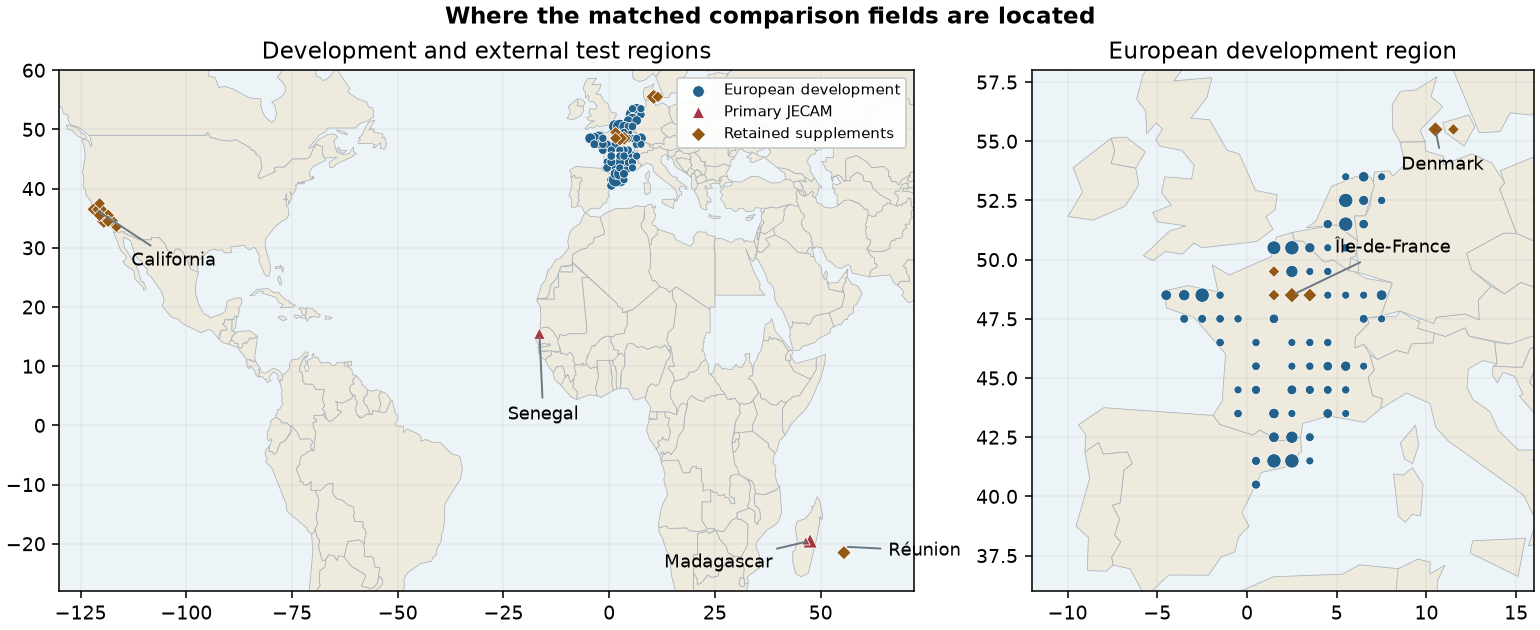

| Where | What it supplies |
| --- | --- |
| Spain, France, and the Netherlands | European development fields from Sen4AgriNet, FranceCrops, and EuroCrops |
| Madagascar’s tropical central highlands | JECAM fields with records for carrot, cabbage, and potato |
| Senegal | JECAM cabbage fields in the matched benchmark |
| California | Supplemental carrot fields from California DWR |
| Denmark | Supplemental cabbage fields from Denmark Marker |
| Île-de-France and Réunion | Supplemental CropHarvest potato fields |
| Paoay, Atok | Target area for future local checks |

**Why** · Madagascar gives us a tropical highland comparison with small fields and records of all three crops. It gives us a starting point for thinking about Paoay. Accuracy in Paoay still needs a local field test.

[Dataset register](../docs/classification_dataset_register.md) · [Final matched coverage](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/test_population_coverage.csv)

### 3. Use one kind of satellite imagery

We need **Sentinel-2 Level-2A surface reflectance** at the labelled fields over time. It measures how much light the ground reflects after accounting for the atmosphere. Repeated images show how the crop changes as it grows.

| Dataset | Imagery in or used by the source | How it differs from the input we need |
| --- | --- | --- |
| Sen4AgriNet | Multi-date Sentinel-2 imagery | **Same satellite.** We build half-month summaries with the same cloud rules and grid used for the other sources. |
| FranceCrops | Sentinel-2 Level-2A time series | **Same satellite and product level.** Our pipeline applies one cloud mask, grid, and half-month schedule across every source. |
| EuroCrops | Dutch parcel boundaries and crop declarations | **Field records only** in the release we used. We need to collect the Sentinel-2 time series separately. |
| CropHarvest JECAM | Sentinel-2 and Sentinel-1 in the wider package | **Includes radar.** Our classifier uses a standardized Sentinel-2 optical time series. |
| CropHarvest non-JECAM | Sentinel-2 and Sentinel-1 in the wider package | **Includes radar.** We use the same Sentinel-2 optical input as for JECAM. |
| California DWR | Crop surveys supported by imagery | We collect the standardized Sentinel-2 series for the surveyed fields. |
| Denmark Marker | Declared field boundaries and crop codes | We collect the same Sentinel-2 series for the declared fields. |

We use the **field locations listed in each dataset** to query Google Earth Engine for Sentinel-2 imagery from the reference year. The crop labels tell us what was recorded at those locations.

**Why** · One imagery archive and a shared set of processing rules give every field comparable measurements. We can skip downloading and harmonizing separate imagery packages.

[Sen4AgriNet benchmark](https://arxiv.org/abs/2204.00951) · [FranceCrops dataset](https://huggingface.co/datasets/saget-antoine/francecrops) · [EuroCrops parcel data](https://essd.copernicus.org/articles/18/4075/2026/essd-18-4075-2026.html) · [CropHarvest benchmark](https://github.com/nasaharvest/cropharvest) · [Project collection rules](../docs/collection.md)

### 4. Queue it, disconnect, collect it later

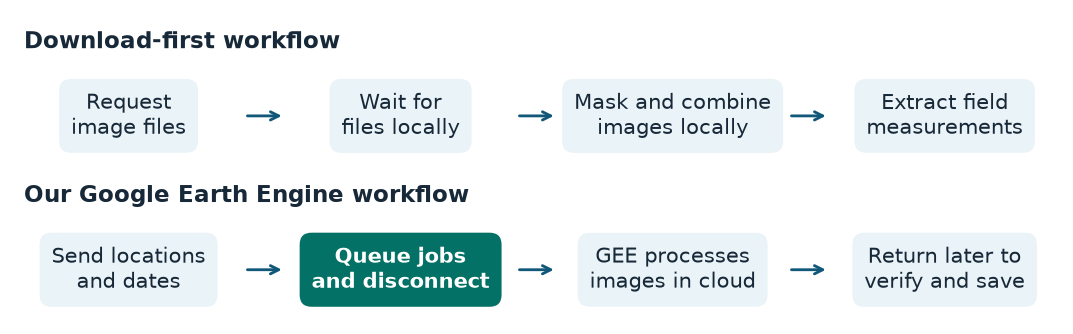

**The workaround** · Submit the jobs and save their task IDs. Once Earth Engine accepts them, the laptop can disconnect while the jobs wait in the queue and run in the cloud. Come back online later to find the finished jobs, retrieve and verify the outputs, and save them locally.

### The Earth Engine settings that matter

| Setting | What we used | Why |
| --- | --- | --- |
| Satellite imagery | Harmonized Sentinel-2 Level-2A surface reflectance | Every field starts with the same kind of measurement of light reflected from the ground. |
| Date range | The full year in the crop record | Each request covers the recorded year. We can choose the growing months later using the saved imagery. |
| Cloud and shadow filter | Keep pixels with a cloud probability below 40%. Also remove cloud shadows and pixels with missing cloud scores. | Clouds and shadows hide the crop and can distort how green it looks. |
| Pixel grid | Line up the bands on the same 10 m grid | Each band describes the same location. Lining them up adds no new detail to the coarser bands. |
| Half-month summary | Combine images taken on the same day, then take the middle value (median) of the clear readings across days in each half-month | It gives us 24 regular time slots for the year and reduces the effect of an unusually high or low reading. |

**Why** · The laptop is free while Earth Engine works, and we can resume from saved task IDs. We transfer the results needed for the fields and can reuse the verified archive for later analysis.

[Collection guide](../docs/collection.md) · [Imagery settings](../docs/methodology.md#candidate-sampling-and-imagery) · [Saved imagery formats](../docs/reference/transport.md)

### 5. Which labeled fields entered the comparisons?

A **parcel** is one reference field group. These are the matched fields with usable fixed and green-up inputs in the comparisons shown here.

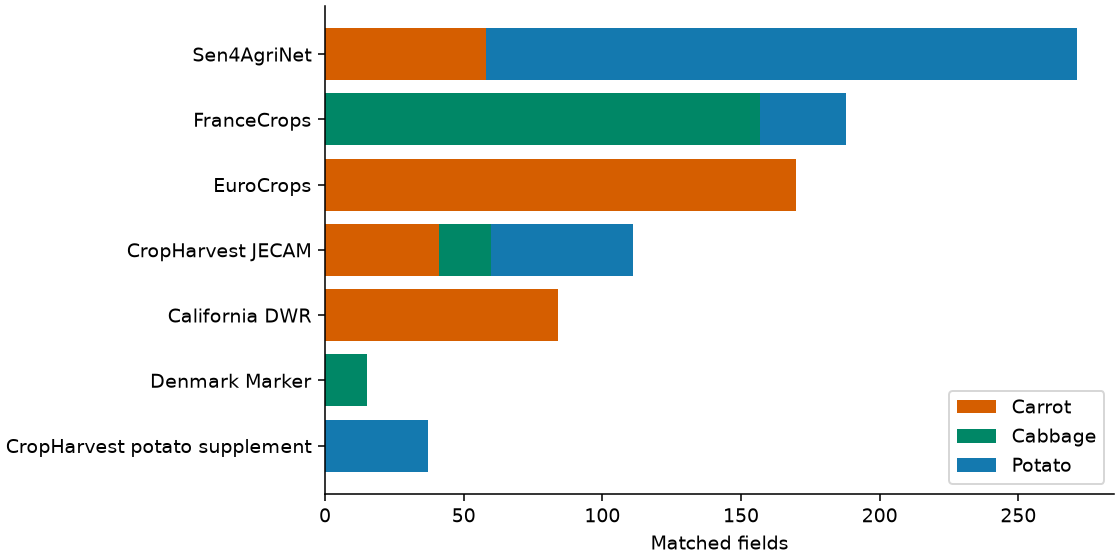

| Source | Carrot fields | Cabbage fields | Potato fields | Total fields |
| --- | ---: | ---: | ---: | ---: |
| Sen4AgriNet | 58 | 0 | 213 | 271 |
| FranceCrops | 0 | 157 | 31 | 188 |
| EuroCrops | 170 | 0 | 0 | 170 |
| CropHarvest JECAM | 41 | 19 | 51 | 111 |
| California DWR | 84 | 0 | 0 | 84 |
| Denmark Marker | 0 | 15 | 0 | 15 |
| CropHarvest potato supplement | 0 | 0 | 37 | 37 |

The European sources supply the training and validation fields. JECAM is the primary external benchmark. California carrot, Denmark cabbage, and CropHarvest potato are supplemental comparisons.

### 6. Collect imagery for the reference year

A Dutch carrot field declared in **2021** tells us where to look and which year to request. We query Earth Engine for Sentinel-2 imagery at that field during 2021.

**Why** · The same field can grow different crops from one year to the next. Using the reference year ties the imagery request to the year covered by the crop record.

[Collection guide](../docs/collection.md)

## Preprocessing

### 7. Turn satellite views into half-month summaries

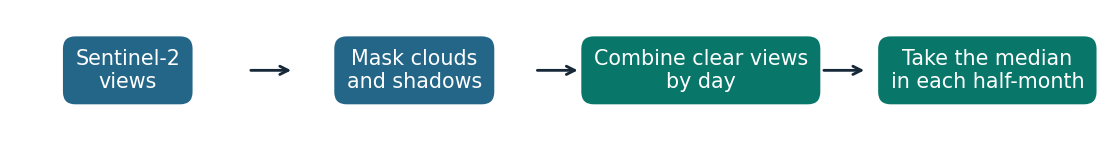

Earth Engine masks clouds, shadows, and invalid readings. It combines usable views taken on the same day, then takes the **middle value (median)** across days within each half-month. The annual archive has **24 expected half-month slots**. A cloudy slot can still have few or zero usable pixels.

**Why** · The median reduces the impact of unusually high or low readings. Regular time slots let us compare the same field across the year.

[Imagery processing rules](../docs/methodology.md#candidate-sampling-and-imagery)

### 8. Which half-months have enough clear imagery?

Start with this FranceCrops cabbage field tile. The two panels show real Sentinel-2 half-month images of the same spot. The grid outlines the **10 pixels selected for sampling**. Hatched cells had no usable reading in that half-month.

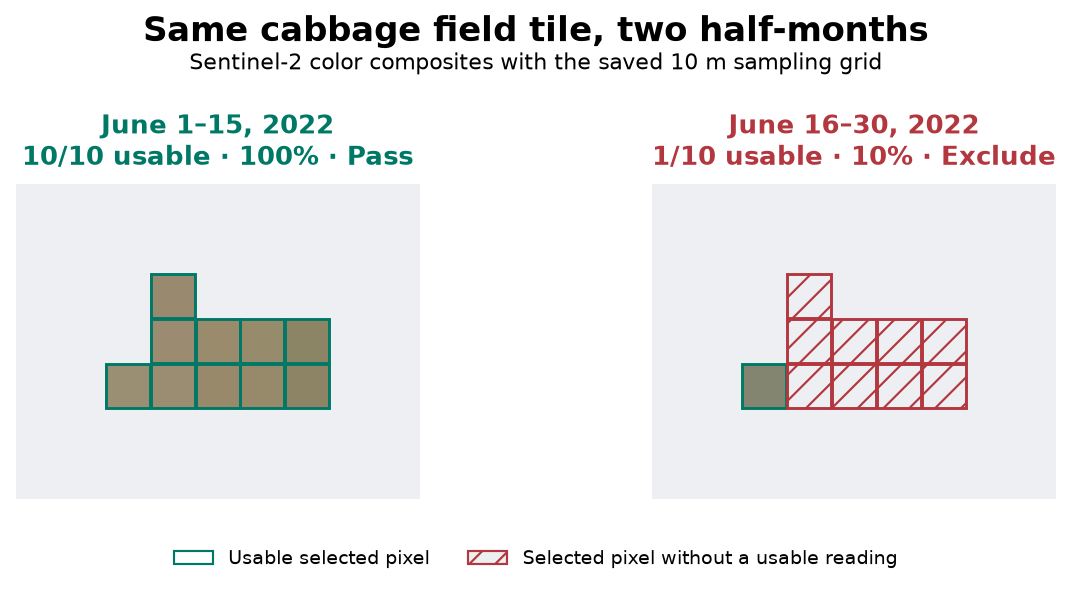

**Where the 10 m buffer comes in** · For FranceCrops, we move the field boundary **10 m inward** during collection, before choosing which pixel centers to sample. Along the edge, a pixel can include a road or a neighboring crop. Sampling farther inside reduces that mix. The audit reuses this saved set of pixels in each half-month. Sen4AgriNet uses its existing crop-mask cells.

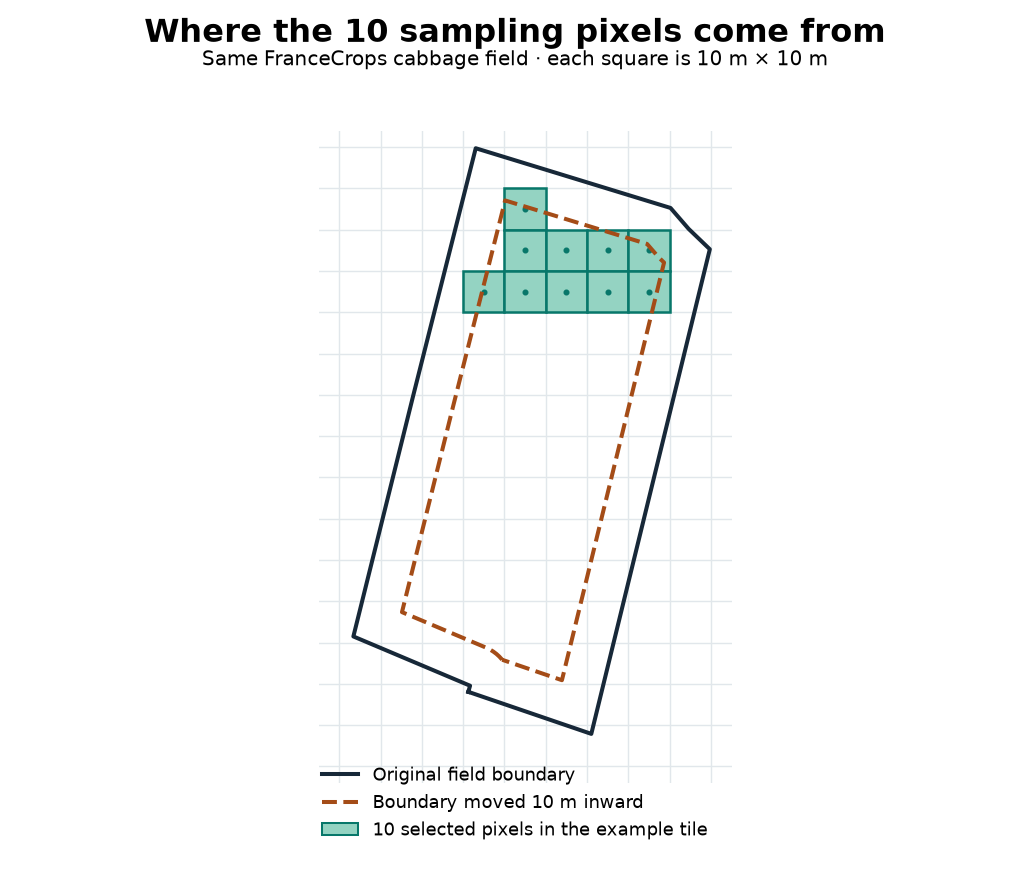

The green squares are the sample pixels in the **same tile shown in the June images**. Their centers lie inside the buffered boundary. They are the 10 pixels used as the denominator for the 80% check in both half-months.

A selected pixel is **usable** if it has at least one clear observation during the half-month and valid readings in all required bands.

**How we decide** · Divide usable pixels by selected pixels. Here, **8 of 10** are needed to reach 80%. June 1–15 passes with **10 of 10**. June 16–30 falls short with **1 of 10**, so we exclude that entire half-month for this tile, including the one usable pixel.

**What Part 9 does with that result** · The fixed May–August window needs all eight half-months. June 16–30 leaves this tile with only **seven passing intervals**, so it contributes no complete pixels to that window. The green-up window is checked against its own eight dates.

| Across the run | Tile × half-month records |
| --- | ---: |
| Before the 80% check · all audited | 172,200 |
| After the check · passed | 131,928 |
| Below 80% · excluded from window inputs | 40,272 |

These counts come from the original imagery audit. A **tile × half-month** is one tile checked for one time slot. The excluded count includes **23,665 saved intervals with zero usable pixels**. There were **0 missing composites**.

**Why** · Part 8 checks one half-month at a time. Part 9 uses those results to find pixels with usable readings in all eight half-months of a window.

<details>
<summary>Other checks from this run</summary>

- The records with loss diagnostics contained **59,564,089 clear pixel-dates** and **132,275,610 pixel-dates lost to clouds or shadows**. A pixel-date is one selected pixel on one satellite observation date. Loss diagnostics were unavailable for **11,664 tile-intervals**.
- The external footprint overlap screen recorded **zero exclusions**.

</details>

[Sampling and buffer rules](../docs/methodology.md#candidate-sampling-and-imagery) · [Quality audit](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/quality.json) · [Observation loss by half-month](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/observation_loss_by_half_month.csv) · [Footprint overlap report](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/test_overlap_exclusions.json)

## Feature engineering

### 9. Turn satellite readings into features and choose the windows

A **feature** is one number the model can use. We build features for each selected pixel in each half-month that passes Part 8.

### Read the five bands

A **band** measures light in one part of the spectrum. The archive stores the band readings as scaled numbers. We multiply them by **0.0001** to get reflectance before calculating the indices.

| Band | Light measured |
| --- | --- |
| **B3** | Green |
| **B4** | Red |
| **B5** | Red-edge, between red and near-infrared |
| **B8** | Near-infrared |
| **B11** | Shortwave-infrared |

### Combine bands into vegetation indices

| Index | How we calculate it | What it helps describe |
| --- | --- | --- |
| **NDVI** | (B8 − B4) ÷ (B8 + B4) | How green the vegetation looks. The rise in NDVI helps guide green-up timing. |
| **NDRE** | (B8 − B5) ÷ (B8 + B5) | Vegetation changes using the red-edge band. |
| **NDMI** | (B8 − B11) ÷ (B8 + B11) | Moisture-related changes in vegetation. |
| **SAVI** | 1.5 × (B8 − B4) ÷ (B8 + B4 + 0.5) | Greenness adjusted for the influence of exposed soil. The final export adds this index. |

**Worked example** · One archived EuroCrops carrot pixel, **May 1–15, 2021**. The band readings are rounded here.

| B3 | B4 | B5 | B8 | B11 |
| ---: | ---: | ---: | ---: | ---: |
| 0.0836 | 0.1003 | 0.1135 | 0.1346 | 0.1626 |

Plug B8 and B4 into NDVI: **(0.1346 − 0.1003) ÷ (0.1346 + 0.1003) ≈ 0.146**. Here are all four index values for that pixel and half-month.

| NDVI | NDRE | NDMI | SAVI |
| ---: | ---: | ---: | ---: |
| 0.146 | 0.085 | -0.094 | 0.070 |

### Keep eight half-months in order

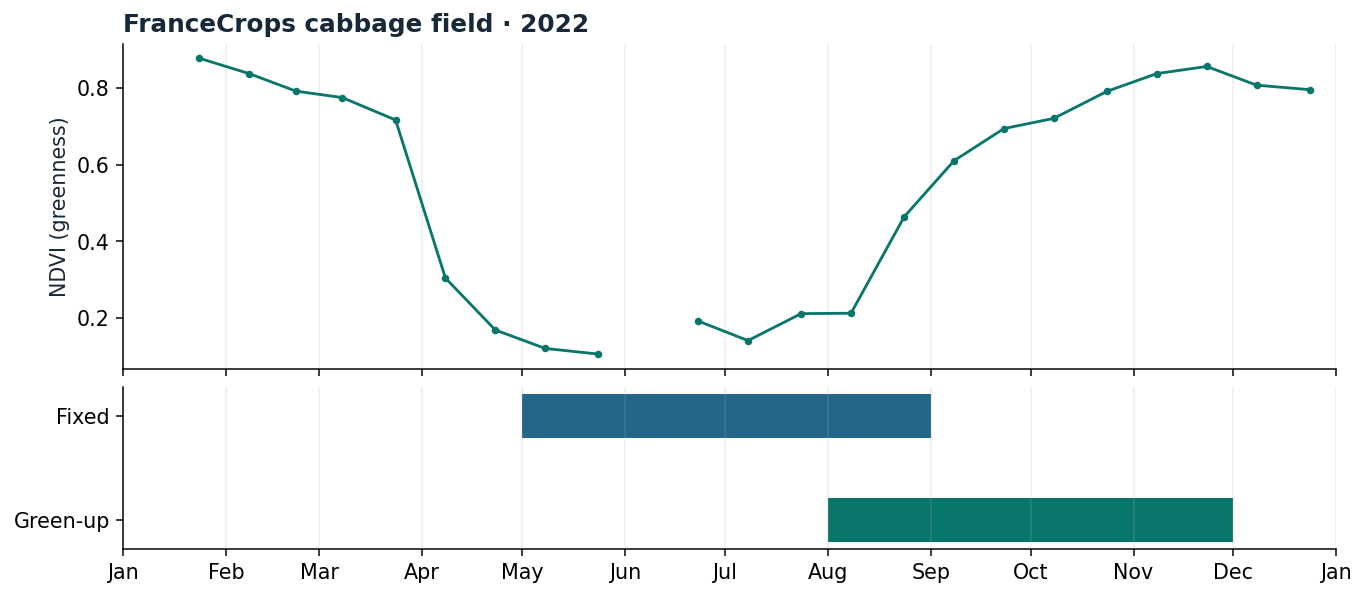

The **fixed** window uses May through August everywhere. The **green-up** method looks for a sustained rise in satellite greenness and starts the window in the estimated onset month. The chart shows the saved half-month NDVI values for the example field. The detector uses the available daily observations to estimate timing. Both windows span **four months and eight half-month slots**.

To qualify as green-up, the rise must hold across later observations and be supported by a rise in NDRE. When observations place a supported rise near a month boundary, or the NDVI thresholds place the same rise in adjacent months, we try both starts. We use the earliest candidate with a complete usable pixel.

For each candidate window, a pixel needs **5 bands + 3 indices in all 8 half-months**, or **64 base values**. A missing value or failed interval makes the sequence incomplete for that window. After matching and splitting, the final export adds **one SAVI value per half-month**, giving **72 inputs per pixel per window**. The inputs stay in time order, from the first half-month to the eighth.

**Why** · The bands describe what the satellite sees. The indices help us read greenness and moisture-related changes. Keeping eight sets of readings in order lets the model use how the field changes across the season.

[Feature formulas](../docs/methodology.md#classifier-features) · [Final window handoff](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/windows/windows.json) · [Saved NDVI series](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/timelines/composite_timelines.csv)

### 10. Match locations for a fair comparison

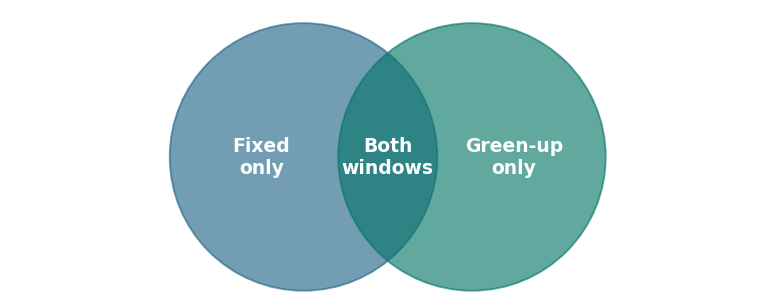

A matched pixel has complete measurements for the **same field and exact location** under both windows. The pipeline removes shared locations between different development fields within each recipe. It then keeps up to **20 shared pixels per field**.

Matching lets us ask how the choice of imagery dates affects predictions while holding the field labels and pixel locations constant.

[Final usable samples](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/usable_samples.csv) · [Shared-location audit](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/quality/development_overlap_exclusions.json)

### 11. Split the development fields

The **629 matched European fields** were split into **472 for training** and **157 for validation**. We stratified by crop and which windows had usable data, aiming for a 75/25 split. All pixels from a field follow the same assignment. The export includes **22 matched fields from newly completed EuroCrops and FranceCrops downloads**, with 7 in training and 15 in validation.

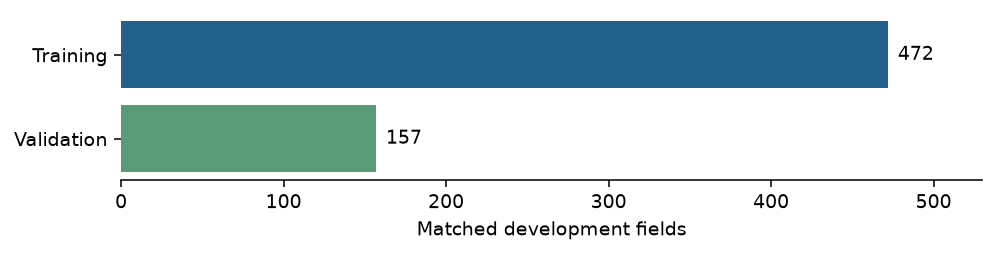

[Saved development assignments](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/development_split.json)

### 12. See what’s ready for training and testing

| Matched set | Carrot fields | Cabbage fields | Potato fields | Total fields | Pixels |
| --- | ---: | ---: | ---: | ---: | ---: |
| Training | 171 | 118 | 183 | 472 | 8,185 |
| Validation | 57 | 39 | 61 | 157 | 2,804 |
| Primary JECAM | 41 | 19 | 51 | 111 | 489 |

Each pixel contributes **72 inputs**. The matched development data meet the training and validation sample targets for all three crops. JECAM has **19 of the 20 target cabbage fields**, and each crop falls below the external target of **400 pixels**.

[Final usable samples](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/usable_samples.csv) · [Test campaign coverage](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/test_population_coverage.csv)

## Training and validation

### 13. Load the matched inputs

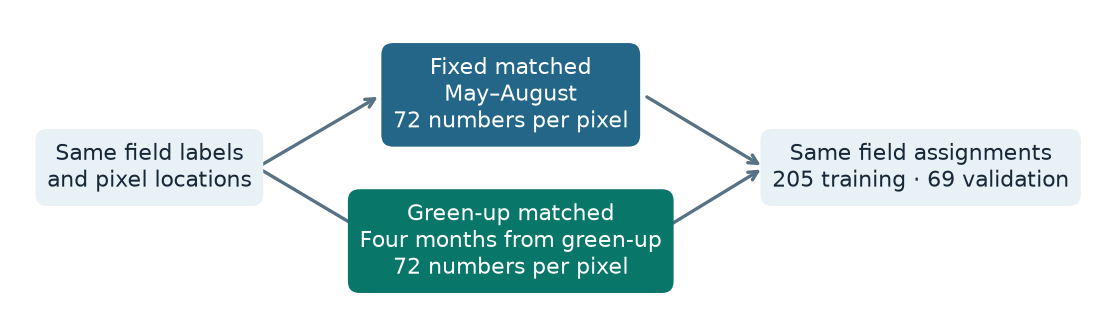

We start with the **72 numbers per pixel** from Part 12 and the recorded crop for each field. We train one model with **fixed May–August** readings and one with **green-up-aligned** readings. Both use the same pixel locations and locked assignments, with **472 fields for training** and **157 for validation**.

**Why** · Comparing the same locations and field assignments makes it easier to see what changes when we use different imagery months.

[Saved field assignments](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/development_split.json)

### 14. Train the Random Forests

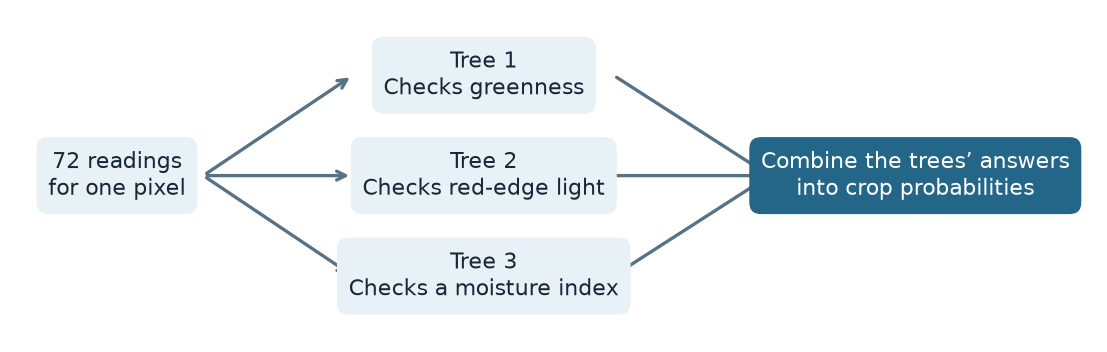

A **decision tree** asks a series of yes/no questions about a pixel’s readings. One might ask whether greenness is above a certain value in a given half-month. Each Random Forest combines **1,000 trees** to estimate how likely the pixel is to be carrot, cabbage, or potato. The picture shows three example trees.

During fitting, we give each crop the **same total weight**, then divide that weight equally among the fields of that crop. All pixels from a field share its weight.

**Why** · Different trees can learn different patterns. Weighting keeps crops and fields with more pixels from having extra influence simply because they supplied more readings.

[Random Forest settings and weighting](../docs/methodology.md#model-selection-and-scoring)

### 15. Validate one field at a time

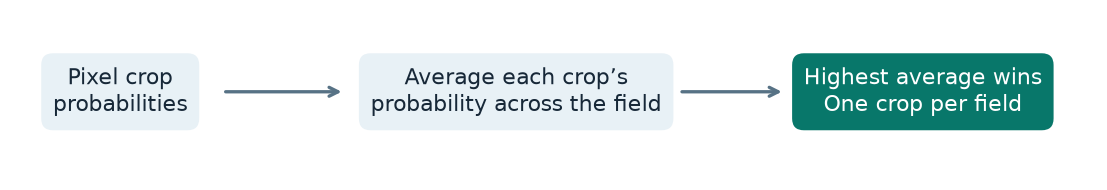

We average crop probabilities across each field’s pixels and use the highest average as the field prediction. Both models are scored on the same **157 validation fields**.

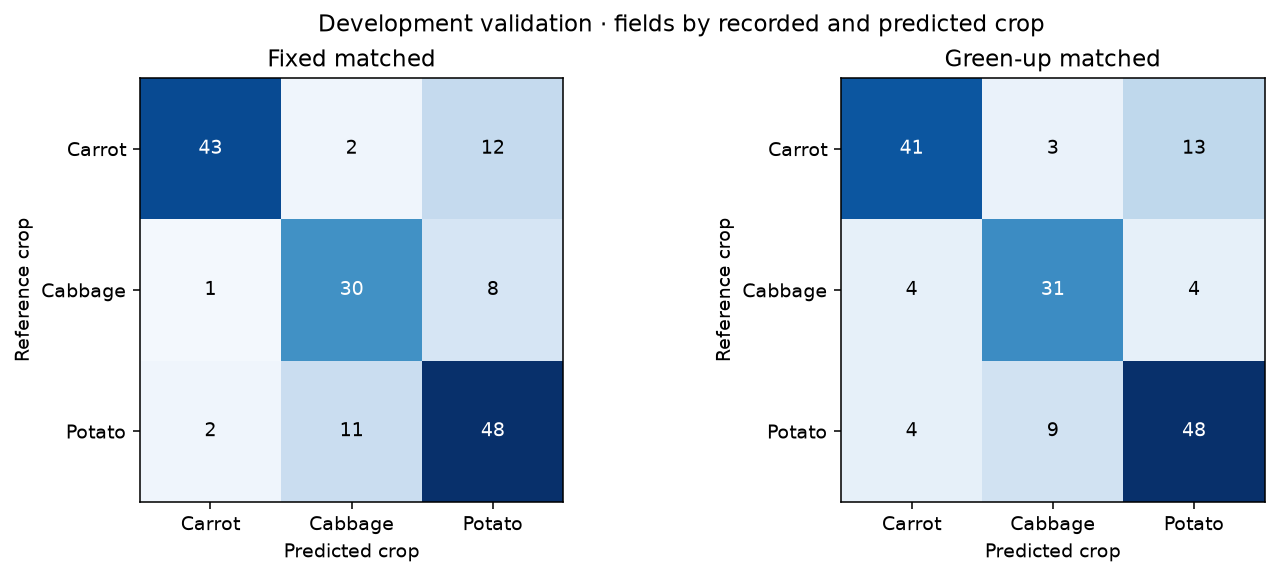

[Saved validation results](../pipeline_outputs/training/run_cf7da69b4caf/validation/validation_candidates.json)

### 16. Compare validation scores and freeze both models

**Macro-F1** averages the three crop F1 scores. F1 balances how often a crop is found with how often predictions for that crop are correct.

| Validation metric | Fixed matched | Green-up matched |
| --- | ---: | ---: |
| Carrot | 0.835 | 0.774 |
| Cabbage | 0.732 | 0.756 |
| Potato | 0.744 | 0.762 |
| **Macro-F1** | **0.770** | **0.764** |
| Overall accuracy | 77.1% (121/157) | 76.4% (120/157) |

The models scored similarly on development validation. We froze both fitted forests before external scoring to see how they would perform on fields from a different region.

[Frozen model manifests](../pipeline_outputs/training/run_cf7da69b4caf/models/models_stage.json)

## External testing

### 17. Establish the transfer baseline for Paoay

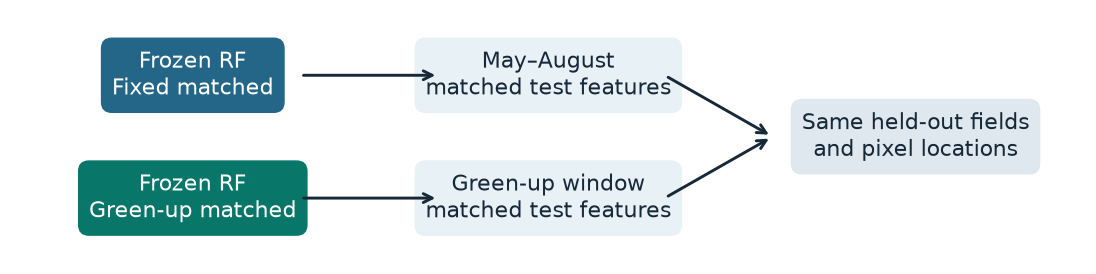

The **Fixed-Matched** forest receives May–August readings. The **Green-up Matched** forest receives its aligned four months. Both predict carrot, cabbage, or potato for the **same independent JECAM fields and pixel locations**. No JECAM labels were used to fit or validate either frozen forest.

This is the external-to-external baseline for SakAI’s upcoming application in **Paoay, Atok**. It measures how the workflow transfers from European development fields to the JECAM benchmark. JECAM had already been examined in earlier experiments, so the planned Paoay accuracy check needs independent local field records.

[External test run receipt](../pipeline_outputs/testing/run_bdac58f74ee0/scores.json)

### 18. Primary result on 111 matched JECAM fields

Both frozen models used **111 fields and 489 matched pixels**. The training-majority baseline predicts potato for every field.

| Field-level result | Fixed matched | Green-up matched | Potato-only baseline |
| --- | ---: | ---: | ---: |
| **Macro-F1** | **0.307** | **0.292** | **0.210** |
| Overall accuracy | 33.3% (37/111) | 31.5% (35/111) | 45.9% (51/111) |

| Crop | Fields | Pixels | Fixed F1 | Green-up F1 |
| --- | ---: | ---: | ---: | ---: |
| Carrot | 41 | 124 | 0.494 | 0.195 |
| Cabbage | 19 | 162 | 0.395 | 0.258 |
| Potato | 51 | 203 | 0.033 | 0.422 |

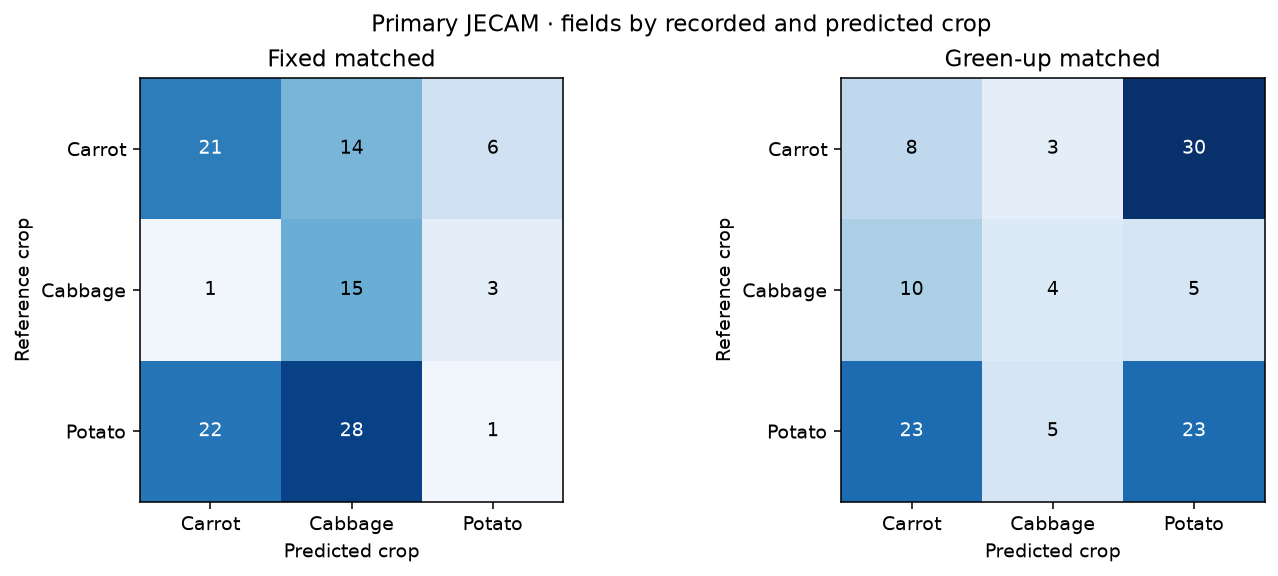

Both models exceeded the potato-only baseline on macro-F1 and fell short of the project’s **0.50 target**. Fixed performed better for carrot and cabbage F1. Green-up alignment performed better for potato F1. The drop from European validation to JECAM shows the challenge of geographic transfer in this study.

[Primary JECAM scores](../pipeline_outputs/testing/run_bdac58f74ee0/reports/test_scores.json) · [Training-majority baseline](../pipeline_outputs/testing/run_bdac58f74ee0/reports/majority_baseline.json)

### 19. How does geographic proximity relate to model transfer?

| Supplemental campaign | Reference crop | Matched fields | Fixed F1 | Green-up F1 |
| --- | --- | ---: | ---: | ---: |
| California DWR | Carrot | 84 | 0.526 | 0.963 |
| Denmark Marker | Cabbage | 15 | 0.800 | 0.929 |
| CropHarvest non-JECAM | Potato | 37 | 0.958 | 0.825 |
| **All retained supplements · macro-F1** | **Three crops** | **136** | **0.595** | **0.814** |

The last row pools the 136 fields and averages the three crop F1 scores calculated on that pool. Pooling lets us count, for example, a cabbage field predicted as carrot as a false carrot prediction.

| Test region | How it relates to the training data | What may help explain the result |
| --- | --- | --- |
| California carrot | California is geographically distant from the European training fields. | Green-up alignment can put the readings at more comparable growth stages when crop calendars differ. That may help explain why green-up scored higher here. |
| Denmark cabbage | Denmark is near the northern European development region. The training set includes cabbage from FranceCrops. | More comparable temperate growing conditions may help the model recognize the cabbage signal. Green-up alignment may also help account for differences in seasonal timing. |
| CropHarvest potato in Île-de-France and Réunion | Île-de-France is in mainland France, where we also had training data. Réunion is farther from the European training region and has different growing conditions. | The strong supplemental potato results are consistent with training on fields that better represent the area being tested, especially for the larger mainland group. Crop calendars, management, and imagery coverage can contribute too. |

These comparisons suggest why it may help to collect **Paoay training fields with growing conditions similar to the area we plan to map**. The study did not isolate climate or distance as the cause of the differences.

[Saved supplemental predictions](../pipeline_outputs/testing/run_bdac58f74ee0/predictions) · [External results by campaign](../pipeline_outputs/testing/run_bdac58f74ee0/reports/diagnostics/results.md)


### 20. Why did the models struggle when tested in a different region?

The models scored about **0.77 macro-F1** on matched European validation fields and about **0.30** on matched JECAM fields in **Madagascar and Senegal**. The validation results show how well the models recognized crops within the European development data. JECAM asks whether the patterns they learned also work across different growing regions.

| Limitation | Why it can affect crop recognition |
| --- | --- |
| **Climate and seasonal timing** | Temperature, rainfall, and elevation can shift when a crop greens up and how quickly it develops. A fixed calendar window can capture different growth stages in different regions. Green-up alignment can bring the imagery closer to comparable stages, but it still relies on an estimated onset. |
| **Farming practices and field appearance** | Planting schedules, irrigation, varieties, and field size can change what the satellite sees for the same crop. A model trained in Europe may have learned patterns that are common in those fields but less common in Madagascar or Senegal. |
| **Imagery and reference coverage** | Gaps in clear imagery can leave fewer usable views of important growth stages. JECAM had only **19 cabbage fields**, and all three crops fell below the **400-pixel target**. Small samples make it harder to tell which patterns hold across whole regions. |

**Nearby or similar fields can help.** Both models recognized potato more often in **Île-de-France**, near European training fields, than in **Réunion**. Mainland training fields may better represent the climate, crop calendar, or practices of the mainland test fields. Distance alone cannot explain the pattern. The green-up model also recognized carrot well in geographically distant **California**, showing why crop timing and other growing conditions matter when judging whether a training field is a good match.

For **Paoay**, prioritize dated labels from nearby fields that represent the local elevation, weather, planting seasons, and farm practices. Fields farther away can also contribute where their growing conditions are comparable. The Madagascar and Senegal adaptation experiment shows how to test the value of adding local labels. Fit with some representative fields and measure accuracy on independent Paoay fields held out from training.

[Saved external diagnostics](../pipeline_outputs/testing/run_bdac58f74ee0/reports/diagnostics/results.md) · [Paoay field observations](../docs/paoay_workflow.md#field-observations)


## Experiments

### Can training on more representative local fields help?

Starting from the frozen green-up matched model, we refit with the same **23 labeled fields from Madagascar and Senegal** at four relative parcel weights. These fields come from the regions where we evaluate transfer. We held out geographic blocks and scored the frozen model and all four refits on the **same 88 fields**. The held-out group contains **35 carrot, 12 cabbage, and 41 potato fields**.

| Local parcel weight | Macro-F1 | Carrot F1 | Cabbage F1 | Potato F1 |
| --- | ---: | ---: | ---: | ---: |
| Frozen (no local fields) | 0.261 | 0.179 | 0.200 | 0.404 |
| 1× | 0.657 | 0.453 | 0.800 | 0.718 |
| 2× | 0.657 | 0.453 | 0.800 | 0.718 |
| 3× | 0.702 | 0.509 | 0.857 | 0.740 |
| 4× | 0.702 | 0.509 | 0.857 | 0.740 |

Adding local labels lifted macro-F1 from **0.261 to 0.657** at normal weight. The 3× and 4× refits tied at **0.702**. These scores describe one exploratory split on previously examined JECAM data. The experiment tests adding labels from the same regions, while the contribution of factors such as crop calendar and growing conditions remains open.

For Paoay, this motivates a similar comparison: start with the external baseline, add dated labels from fields that represent the local growing conditions, and keep independent Paoay fields for the accuracy check.

[Weight comparison](../pipeline_outputs/testing/run_ca5c900c415b/jecam_weight_comparison.csv) · [Adaptation and holdout split](../pipeline_outputs/testing/run_ca5c900c415b/jecam_site_split.csv)

### Feature and classifier comparisons on the final development split

We reran these comparisons on **472 matched training fields** and scored every variant on the **same 157 validation fields**. Both window methods use the same field assignments. Macro-F1 gives carrot, cabbage, and potato equal weight.

| Experiment | What changed | Fixed matched | Green-up matched |
| --- | --- | ---: | ---: |
| Baseline RF | 72 interval inputs | 0.770 | 0.764 |
| Shape only | 48 changes, slopes, and other shape measurements | 0.820 | 0.734 |
| Intervals + shape | 72 interval inputs plus 48 shape measurements | 0.790 | 0.750 |
| Bands only | 40 band readings | 0.734 | 0.748 |
| Indices only | 32 vegetation indices | 0.774 | 0.739 |
| One half-month | 9 inputs from the fourth half-month | 0.681 | 0.632 |
| RF tuning | Settings selected using geographically grouped training folds | 0.770 | 0.769 |
| RBF SVM | 72 inputs and preset settings | 0.793 | 0.779 |
| XGBoost | 72 inputs and preset settings | 0.790 | 0.738 |
| Field-median RF | 72 median measurements per field | 0.721 | 0.712 |

The highest validation macro-F1 came from **Shape only** for fixed and **RBF SVM** for green-up. The RF tuning check used five geographically grouped folds within training. It selected minimum leaf size 8 for fixed and minimum leaf size 4 for green-up.

[Validation macro-F1 results](../pipeline_outputs/training/run_bc1834d2ac7d/validation_macro_f1.csv) · [Settings and field predictions](../pipeline_outputs/training/run_bc1834d2ac7d/validation_details.json)

### Two exploratory variants on the 111-field JECAM benchmark

We refit the same two designs used in the earlier external comparison and scored them on the **same 111 fields and 489 matched pixels** as the current frozen baseline. The designs were specified before this scoring run.

| Window | Frozen baseline macro-F1 | Exploratory model | Exploratory macro-F1 |
| --- | ---: | --- | ---: |
| Fixed matched | 0.307 | XGBoost | 0.297 |
| Green-up matched | 0.292 | RF tuning | 0.302 |

JECAM stayed outside fitting and validation for these variants. It had already been examined in earlier experiments, so these scores describe the historical benchmark. The upcoming Paoay accuracy check will use independent local fields.

[Exploratory JECAM scores](../pipeline_outputs/testing/run_d6ce2e68cd80/jecam_macro_f1.json) · [Earlier experiment archive](../pipeline_outputs/training/run_81de4b6717e9/matched_validation_experiments.json)
